# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Muhammad Taraz
- **Roll No:** 023-24-0259
- **Section:** H
- **Date:** 18-11-2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

> Note: The uploaded manual and template both identify this exercise as Lab 12. The original template has been retained.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report
)

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)


Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16 check
result = predict([0.6, 0.8], [2, 3], -2)
print("Slide 16 prediction:", result)

# Slide 17 check
w = [1, -0.5]
b = 0.5
inputs = [[1, 1], [2, 1], [0, 3]]
predictions = [predict(w, x, b) for x in inputs]
print("Slide 17 predictions:", predictions)


Slide 16 prediction: 1
Slide 17 predictions: [1, 1, 0]


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
and_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
and_y = np.array([0, 0, 0, 1])

w = np.array([0.2, -0.1], dtype=float)
b = 0.0
eta = 0.1
mistakes = 0

for row, target in zip(and_X, and_y):
    z = weighted_sum(w, row, b)
    y_hat = step_function(z)
    error = target - y_hat

    if error != 0:
        mistakes += 1
        w = w + eta * error * row
        b = b + eta * error

    print(f"x={row}, y={target}, z={z:.2f}, y_hat={y_hat}, "
          f"e={error}, new w={w}, new b={b:.2f}")

print("\nFinal w:", w)
print("Final b:", b)
print("Number of mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")


x=[0 0], y=0, z=0.00, y_hat=1, e=-1, new w=[ 0.2 -0.1], new b=-0.10
x=[0 1], y=0, z=-0.20, y_hat=0, e=0, new w=[ 0.2 -0.1], new b=-0.10
x=[1 0], y=0, z=0.10, y_hat=1, e=-1, new w=[ 0.1 -0.1], new b=-0.20
x=[1 1], y=1, z=-0.20, y_hat=0, e=1, new w=[0.2 0. ], new b=-0.10

Final w: [0.2 0. ]
Final b: -0.1
Number of mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    w = np.zeros(X.shape[1], dtype=float)
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        epoch_mistakes = 0

        for row, target in zip(X, y):
            y_hat = step_function(weighted_sum(w, row, b))
            error = target - y_hat

            if error != 0:
                w = w + eta * error * row
                b = b + eta * error
                epoch_mistakes += 1

        mistakes.append(epoch_mistakes)
        if epoch_mistakes == 0:
            break

    return w, b, mistakes

or_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
or_y = np.array([0, 1, 1, 1])
or_w, or_b, or_mistakes = train_perceptron(or_X, or_y)

print("OR gate final weights:", or_w)
print("OR gate final bias:", or_b)
print("Mistakes per epoch:", or_mistakes)


OR gate final weights: [0.1 0.1]
OR gate final bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

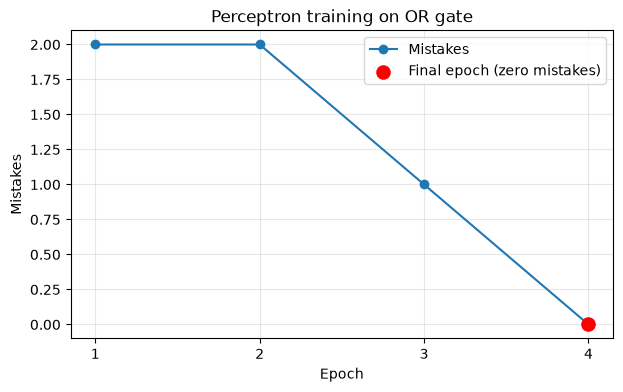

In [5]:
# Task 2.2
epochs = np.arange(1, len(or_mistakes) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, or_mistakes, marker="o", label="Mistakes")
plt.scatter(epochs[-1], or_mistakes[-1], color="red", s=90,
            label="Final epoch (zero mistakes)", zorder=3)
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


**Interpretation:** The number of mistakes decreases as the perceptron learns the OR gate. It reaches zero mistakes, so the training stops after the final zero-mistake epoch.


## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

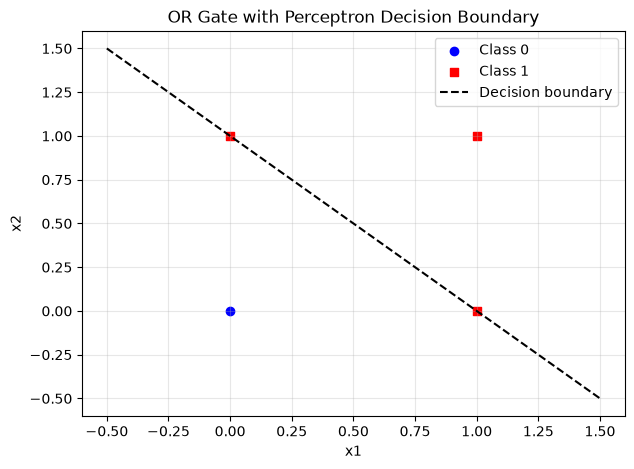

In [6]:
# Task 3.1
def plot_boundary(ax, w, b):
    w = np.asarray(w, dtype=float)
    if abs(w[1]) > 1e-12:
        x1 = np.linspace(-0.5, 1.5, 100)
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, "k--", label="Decision boundary")
    elif abs(w[0]) > 1e-12:
        x1_boundary = -b / w[0]
        ax.axvline(x1_boundary, color="black", linestyle="--",
                   label="Decision boundary")
    else:
        ax.text(0.05, 0.95, "No boundary (w = 0)", transform=ax.transAxes,
                va="top")

plt.figure(figsize=(7, 5))
ax = plt.gca()
ax.scatter(or_X[or_y == 0, 0], or_X[or_y == 0, 1],
           color="blue", marker="o", label="Class 0")
ax.scatter(or_X[or_y == 1, 0], or_X[or_y == 1, 1],
           color="red", marker="s", label="Class 1")
plot_boundary(ax, or_w, or_b)
ax.set_title("OR Gate with Perceptron Decision Boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


**Interpretation:** The black dashed line represents points where the weighted sum is zero. The side where `w1*x1 + w2*x2 + b >= 0` is predicted as class 1.


### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

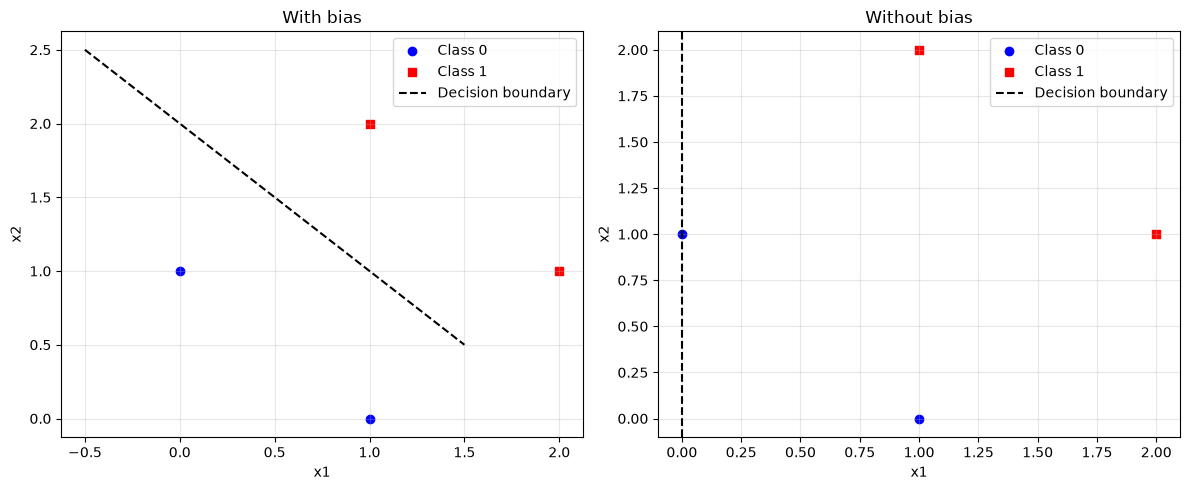

With bias mistakes: [2, 3, 1, 0]
Without bias mistakes: [3, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2]
No-bias converged: False


In [7]:
# Task 3.2
def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    w = np.zeros(X.shape[1], dtype=float)
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        epoch_mistakes = 0
        for row, target in zip(X, y):
            y_hat = step_function(np.dot(w, row))  # bias remains fixed at zero
            error = target - y_hat
            if error != 0:
                w = w + eta * error * row
                epoch_mistakes += 1
        mistakes.append(epoch_mistakes)
        if epoch_mistakes == 0:
            break
    return w, b, mistakes

bias_X = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
bias_y = np.array([0, 0, 1, 1])

w_bias, b_bias, mistakes_bias = train_perceptron(bias_X, bias_y)
w_no_bias, b_no_bias, mistakes_no_bias = train_perceptron_no_bias(bias_X, bias_y)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, weights, bias, title in [
    (axes[0], w_bias, b_bias, "With bias"),
    (axes[1], w_no_bias, b_no_bias, "Without bias")
]:
    ax.scatter(bias_X[bias_y == 0, 0], bias_X[bias_y == 0, 1],
               color="blue", marker="o", label="Class 0")
    ax.scatter(bias_X[bias_y == 1, 0], bias_X[bias_y == 1, 1],
               color="red", marker="s", label="Class 1")
    plot_boundary(ax, weights, bias)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("With bias mistakes:", mistakes_bias)
print("Without bias mistakes:", mistakes_no_bias)
print("No-bias converged:", mistakes_no_bias[-1] == 0)


**Interpretation:** The model with bias can move its boundary away from the origin. The no-bias model does not converge for this dataset because its boundary is forced to pass through the origin.


## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes: 4
Final weights: [-0.1  0. ]
Final bias: 0.0


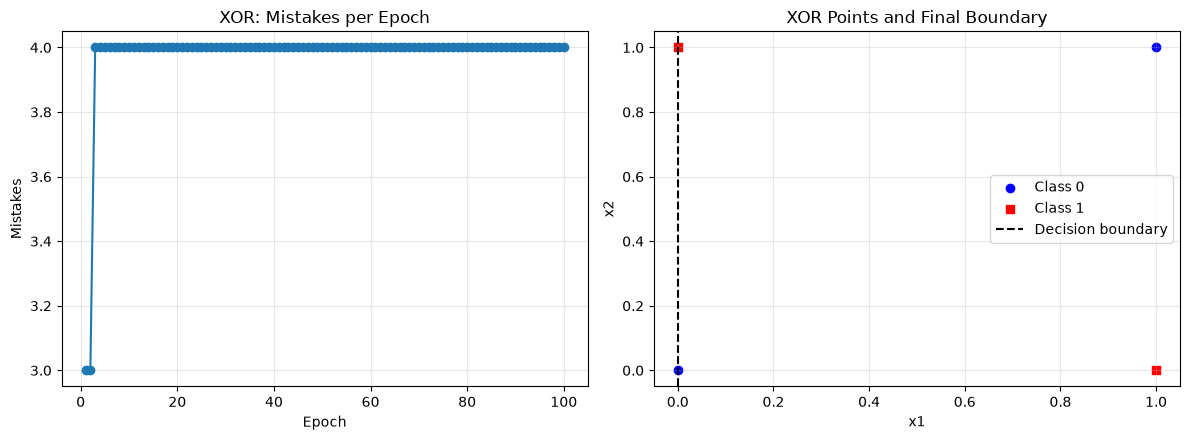

In [8]:
# Task 4.1
xor_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
xor_y = np.array([0, 1, 1, 0])

xor_w, xor_b, xor_mistakes = train_perceptron(
    xor_X, xor_y, eta=0.1, max_epochs=100
)
print("Final mistakes:", xor_mistakes[-1])
print("Final weights:", xor_w)
print("Final bias:", xor_b)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(range(1, len(xor_mistakes) + 1), xor_mistakes,
             marker="o")
axes[0].set_title("XOR: Mistakes per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mistakes")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(xor_X[xor_y == 0, 0], xor_X[xor_y == 0, 1],
                color="blue", marker="o", label="Class 0")
axes[1].scatter(xor_X[xor_y == 1, 0], xor_X[xor_y == 1, 1],
                color="red", marker="s", label="Class 1")
plot_boundary(axes[1], xor_w, xor_b)
axes[1].set_title("XOR Points and Final Boundary")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The perceptron does not reach zero mistakes within 100 epochs. XOR is not linearly separable, so one straight decision boundary cannot correctly separate its two classes.


### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    points = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    required = np.array([0, 1, 1, 0])
    values = points @ np.asarray(w) + b
    predictions = (values >= 0).astype(int)
    return np.array_equal(predictions, required)

random_w = np.random.uniform(-5, 5, (10000, 2))
random_b = np.random.uniform(-5, 5, 10000)

passing = []
for weights, bias in zip(random_w, random_b):
    if check_xor(weights, bias):
        passing.append((weights.copy(), bias))

print("Number of passing triples:", len(passing))
if len(passing) == 0:
    print("No solution found")
else:
    print("First passing triple:", passing[0])


Number of passing triples: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X = iris.data[:, (2, 3)]
y = (iris.target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

iris_perceptron = Perceptron(random_state=42)
iris_perceptron.fit(X_train, y_train)
y_pred = iris_perceptron.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=["Rest", "Setosa"], zero_division=0))
print("coef_:", iris_perceptron.coef_)
print("intercept_:", iris_perceptron.intercept_)


Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** `coef_` contains the learned weights (w), while `intercept_` contains the bias (b). The confusion matrix and report show how well the model separates Setosa from the other two Iris classes.


### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

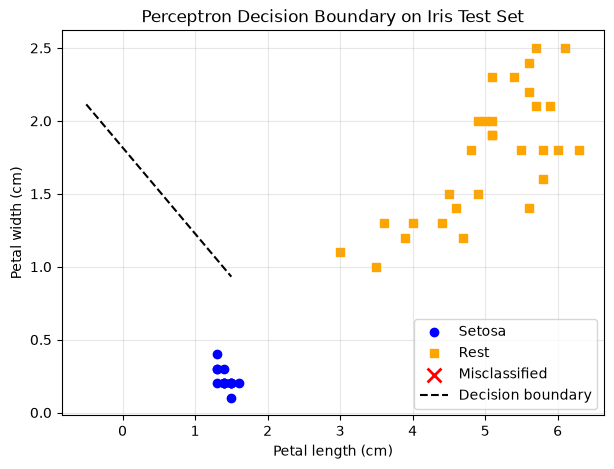

Number of misclassified test points: 0


In [11]:
# Task 5.2
test_pred = iris_perceptron.predict(X_test)
misclassified = test_pred != y_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
           color="blue", label="Setosa", marker="o")
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1],
           color="orange", label="Rest", marker="s")
ax.scatter(X_test[misclassified, 0], X_test[misclassified, 1],
           color="red", marker="x", s=100, linewidths=2,
           label="Misclassified")
plot_boundary(ax, iris_perceptron.coef_[0],
              iris_perceptron.intercept_[0])
ax.set_title("Perceptron Decision Boundary on Iris Test Set")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

print("Number of misclassified test points:", int(misclassified.sum()))


**Interpretation:** The boundary is straight because a perceptron uses a linear weighted sum. The number printed above is the count of test samples whose predicted class does not match the true class.


### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
learning_rates = [0.001, 0.1, 10.0]
rate_results = []
rate_predictions = {}

for rate in learning_rates:
    model = Perceptron(eta0=rate, random_state=42)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rate_predictions[rate] = predictions
    rate_results.append({
        "eta0": rate,
        "accuracy": accuracy_score(y_test, predictions),
        "n_iter_": model.n_iter_,
        "coef_": model.coef_[0].copy()
    })

print(f"{'eta0':<10}{'accuracy':<12}{'n_iter_':<10}coef_")
for item in rate_results:
    print(f"{item['eta0']:<10}{item['accuracy']:<12.4f}"
          f"{item['n_iter_']:<10}{item['coef_']}")

print("\nPredictions identical across all learning rates:",
      np.array_equal(rate_predictions[0.001], rate_predictions[0.1])
      and np.array_equal(rate_predictions[0.1], rate_predictions[10.0]))


eta0      accuracy    n_iter_   coef_
0.001     1.0000      6         [-0.0013 -0.0022]
0.1       1.0000      7         [-0.13 -0.22]
10.0      1.0000      7         [-13. -22.]

Predictions identical across all learning rates: True


**Interpretation:** All three learning rates give the same test predictions and accuracy (1.00) in this run. The coefficient vectors become proportionally larger as `eta0` increases, showing that the learning rate changes the size of updates; here, the direction of the learned boundary stays the same.


## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X_multi = iris.data
y_multi = iris.target

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.30, random_state=42, stratify=y_multi
)

multi_perceptron = Perceptron(random_state=42, max_iter=1000)
multi_perceptron.fit(X_train_multi, y_train_multi)
multi_pred = multi_perceptron.predict(X_test_multi)

print("Classification report:\n",
      classification_report(y_test_multi, multi_pred,
                             target_names=iris.target_names, zero_division=0))
cm_multi = confusion_matrix(y_test_multi, multi_pred)
print("Confusion matrix:\n", cm_multi)
print("coef_ shape:", multi_perceptron.coef_.shape)


Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_ shape: (3, 4)


**Interpretation:** Each row of `coef_` contains the weights for one one-vs-rest classifier, so its shape is three rows by four features. Versicolor is the hardest class in this run because the model correctly classifies none of its 15 test samples, confusing 14 with Setosa and 1 with Virginica.


### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
logistic_model = LogisticRegression(random_state=42, max_iter=200)
logistic_model.fit(X_train_multi, y_train_multi)
logistic_pred = logistic_model.predict(X_test_multi)

comparison = [
    ("Perceptron",
     accuracy_score(y_test_multi, multi_pred),
     f1_score(y_test_multi, multi_pred, average="macro")),
    ("Logistic Regression",
     accuracy_score(y_test_multi, logistic_pred),
     f1_score(y_test_multi, logistic_pred, average="macro"))
]

print(f"{'Model':<22}{'Accuracy':<12}{'Macro-F1':<12}")
for name, accuracy, macro_f1 in comparison:
    print(f"{name:<22}{accuracy:<12.4f}{macro_f1:<12.4f}")


Model                 Accuracy    Macro-F1    
Perceptron            0.6667      0.5499      
Logistic Regression   0.9333      0.9333      


**Interpretation:** Logistic Regression can perform better because its sigmoid-based output is smooth and its gradient provides useful learning information. The perceptron's step function only gives a right-or-wrong class decision, so it has less information for adjusting weights.


## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Answer:**  
Given `w = [0.5, -0.3]`, `b = 0.2`, `eta = 0.1`, `x = [1, 2]`, and `y = 0`.

1. Weighted sum: `z = (0.5 × 1) + (-0.3 × 2) + 0.2 = 0.1`.
2. Since `z >= 0`, prediction `ŷ = 1`.
3. Error: `e = y - ŷ = 0 - 1 = -1`.
4. Update: `w1 = 0.5 + 0.1(-1)(1) = 0.4`.
5. Update: `w2 = -0.3 + 0.1(-1)(2) = -0.5`.
6. Bias: `b = 0.2 + 0.1(-1) = 0.1`.

**Final values:** `w = [0.4, -0.5]`, `b = 0.1`.


**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Answer:**  
The decision boundary is `0.3x1 + 0.2x2 - 0.4 = 0`.

Solving for `x2` gives `x2 = 2 - 1.5x1`. For point `(1, 1)`, the weighted sum is `0.3 + 0.2 - 0.4 = 0.1`. Since it is positive, the point is on the class 1 side and its prediction is `ŷ = 1`.


**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**Answer:**

**(a) Algebra:** The XOR conditions require:
- For `(0,0)`: `b < 0`.
- For `(0,1)`: `w2 + b >= 0`.
- For `(1,0)`: `w1 + b >= 0`.
- For `(1,1)`: `w1 + w2 + b < 0`.

Adding the middle two inequalities gives `w1 + w2 + 2b >= 0`. But the first and last conditions give `w1 + w2 + 2b < 0` (because `w1 + w2 + b < 0` and `b < 0`). This is a contradiction, so no single linear perceptron can satisfy all four conditions.

**(b) XOR sketch:**

```text
x2
1     (0,1) Class 1       (1,1) Class 0

0     (0,0) Class 0       (1,0) Class 1
      0                    1          x1
```

The two class 1 points are on opposite corners, and the class 0 points occupy the other two corners. One straight line cannot separate these alternating classes.

**(c) Architectural change:** Add a hidden layer with nonlinear activation functions. A multilayer perceptron can learn XOR.


**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [15]:
# Q4
X_extended = iris.data[:, (0, 2, 3)]
y_extended = (iris.target == 0).astype(int)

X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_extended, y_extended, test_size=0.30, random_state=42, stratify=y_extended
)

extended_model = Perceptron(random_state=42)
extended_model.fit(X_train_ext, y_train_ext)
extended_pred = extended_model.predict(X_test_ext)

extended_accuracy = accuracy_score(y_test_ext, extended_pred)
extended_macro_f1 = f1_score(y_test_ext, extended_pred, average="macro")

print("Features used: sepal length, petal length, petal width")
print("Accuracy:", round(extended_accuracy, 4))
print("Macro-F1:", round(extended_macro_f1, 4))
print("\nOriginal two-feature accuracy:",
      round(accuracy_score(y_test, iris_perceptron.predict(X_test)), 4))
print("Original two-feature macro-F1:",
      round(f1_score(y_test, iris_perceptron.predict(X_test), average="macro"), 4))


Features used: sepal length, petal length, petal width
Accuracy: 1.0
Macro-F1: 1.0

Original two-feature accuracy: 1.0
Original two-feature macro-F1: 1.0


**Analysis:** The original two-feature model and the extended three-feature model both have accuracy 1.00 and macro-F1 1.00 on this test split. Therefore, adding sepal length does not improve either score in this run, although it also does not reduce them.


**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model                 Accuracy    Epochs / iterations   
Hand-built            0.8167      100                   
sklearn               0.7667      14                    

Hand-built final w: [0.25367668 0.03676208]
Hand-built final b: 0.10000000000000003
sklearn final w: [ 1.16050566 -0.19903701]
sklearn final b: 1.0


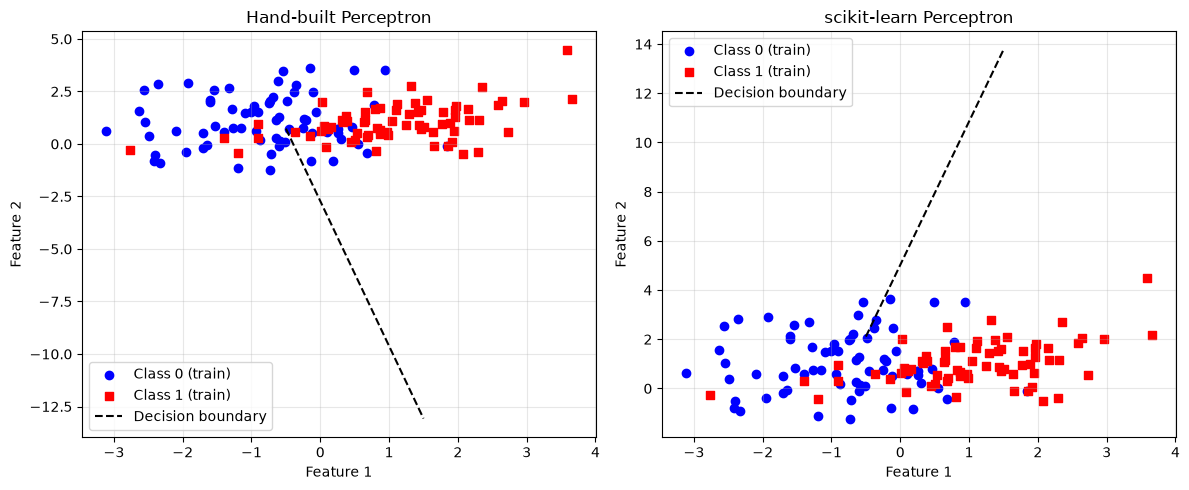

In [16]:
# Q5
synthetic_X, synthetic_y = make_classification(
    n_samples=200, n_features=2, n_redundant=0,
    n_clusters_per_class=1, random_state=42
)

syn_X_train, syn_X_test, syn_y_train, syn_y_test = train_test_split(
    synthetic_X, synthetic_y, test_size=0.30,
    random_state=42, stratify=synthetic_y
)

# Hand-built perceptron
hand_w, hand_b, hand_mistakes = train_perceptron(
    syn_X_train, syn_y_train, eta=0.1, max_epochs=100
)
hand_pred = np.array([
    predict(hand_w, row, hand_b) for row in syn_X_test
])

# scikit-learn perceptron
sk_model = Perceptron(random_state=42, max_iter=1000)
sk_model.fit(syn_X_train, syn_y_train)
sk_pred = sk_model.predict(syn_X_test)

print(f"{'Model':<22}{'Accuracy':<12}{'Epochs / iterations':<22}")
print(f"{'Hand-built':<22}{accuracy_score(syn_y_test, hand_pred):<12.4f}"
      f"{len(hand_mistakes):<22}")
print(f"{'sklearn':<22}{accuracy_score(syn_y_test, sk_pred):<12.4f}"
      f"{sk_model.n_iter_:<22}")
print("\nHand-built final w:", hand_w)
print("Hand-built final b:", hand_b)
print("sklearn final w:", sk_model.coef_[0])
print("sklearn final b:", sk_model.intercept_[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, weights, bias, title in [
    (axes[0], hand_w, hand_b, "Hand-built Perceptron"),
    (axes[1], sk_model.coef_[0], sk_model.intercept_[0],
     "scikit-learn Perceptron")
]:
    ax.scatter(syn_X_train[syn_y_train == 0, 0],
               syn_X_train[syn_y_train == 0, 1],
               color="blue", marker="o", label="Class 0 (train)")
    ax.scatter(syn_X_train[syn_y_train == 1, 0],
               syn_X_train[syn_y_train == 1, 1],
               color="red", marker="s", label="Class 1 (train)")
    plot_boundary(ax, weights, bias)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Analysis:** The table compares test accuracy and the number of training epochs or iterations. The hand-built model reports its final weight vector and bias, while scikit-learn reports the learned values in `coef_` and `intercept_`; small differences are expected because the implementations may use different training details.
